## 1. Import library dan pengaturan

In [1]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Folder project (notebook ini ada di folder notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATASET_RAW = ROOT / "dataset_raw"
HASIL = ROOT / "hasil" / "seleksi_dataset"

KELAS = ["logam", "paper", "plastic"]
FORMAT_OK = {".jpg", ".jpeg", ".png"}
MIN_SISI = 200        # sisi terpendek foto minimal (piksel)
BATAS_KEMBAR = 3      # rata-rata selisih piksel thumbnail (skala 0-255); makin kecil makin ketat

## 2. Fungsi bantu

In [2]:
def baca(path, gray=False):
    """Membaca gambar (aman untuk path Windows). Hasil None jika gagal dibaca."""
    try:
        data = np.fromfile(str(path), np.uint8)
        return cv2.imdecode(data, cv2.IMREAD_GRAYSCALE if gray else cv2.IMREAD_COLOR)
    except Exception:
        return None


def thumbnail(img):
    """Foto diperkecil menjadi 32x32 abu-abu sebagai pembanding duplikat."""
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return cv2.resize(g, (32, 32), interpolation=cv2.INTER_AREA).astype(np.float32).flatten()


def tampilkan(daftar, judul_besar, simpan):
    """daftar berisi pasangan (gambar, judul). Ditampilkan dalam kisi 3 kolom."""
    n = len(daftar)
    kolom = min(3, n)
    baris = int(np.ceil(n / kolom))
    fig, ax = plt.subplots(baris, kolom, figsize=(4.5 * kolom, 4 * baris), squeeze=False)
    for a in ax.ravel():
        a.axis("off")
    for a, (img, judul) in zip(ax.ravel(), daftar):
        a.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        a.set_title(judul, fontsize=9)
    fig.suptitle(judul_besar, fontsize=13, fontweight="bold")
    fig.tight_layout()
    HASIL.mkdir(parents=True, exist_ok=True)
    fig.savefig(simpan, dpi=120)
    plt.show()

## 3. Periksa semua foto (rusak, tidak terbaca, resolusi kecil)

In [3]:
data = []        # satu baris per file
thumb_foto = {}  # (kelas, nama file) -> thumbnail

for kelas in KELAS:
    for p in sorted((DATASET_RAW / kelas).glob("*")):
        if not p.is_file() or p.name.startswith("."):
            continue
        baris = dict(kelas=kelas, file=p.name, lebar=0, tinggi=0,
                     status="dipertahankan", alasan="-", keterangan="")
        if p.suffix.lower() not in FORMAT_OK:
            baris.update(status="ditolak", alasan="format tidak didukung", keterangan=p.suffix)
        else:
            img = baca(p)
            if img is None:
                baris.update(status="ditolak", alasan="tidak terbaca", keterangan="file rusak")
            else:
                h, w = img.shape[:2]
                baris.update(lebar=w, tinggi=h)
                if min(h, w) < MIN_SISI:
                    baris.update(status="ditolak", alasan="resolusi kecil",
                                 keterangan=f"sisi terpendek {min(h, w)} px < {MIN_SISI} px")
                else:
                    thumb_foto[(kelas, p.name)] = thumbnail(img)
        data.append(baris)

if not data:
    raise FileNotFoundError("dataset_raw masih kosong. Taruh foto di dataset_raw/logam, "
                            "dataset_raw/paper, dataset_raw/plastic lalu jalankan ulang notebook ini.")
df = pd.DataFrame(data)
print(f"Jumlah file diperiksa: {len(df)}")

Jumlah file diperiksa: 440


## 4. Cari foto duplikat


In [4]:
layak = df[df["status"] == "dipertahankan"].copy()
layak["piksel"] = layak["lebar"] * layak["tinggi"]
layak = layak.sort_values(["piksel", "kelas", "file"], ascending=[False, True, True])

thumb_tersimpan, nama_tersimpan = [], []
for idx, r in layak.iterrows():
    t = thumb_foto[(r["kelas"], r["file"])]
    if thumb_tersimpan:
        selisih = np.abs(np.array(thumb_tersimpan) - t).mean(axis=1)
        k = int(selisih.argmin())
        if selisih[k] <= BATAS_KEMBAR:
            df.loc[idx, ["status", "alasan", "keterangan"]] = ["ditolak", "duplikat", f"mirip dengan {nama_tersimpan[k]}"]
            continue
    thumb_tersimpan.append(t)
    nama_tersimpan.append(f"{r['kelas']}/{r['file']}")

## 5. Ringkasan hasil seleksi

In [5]:
HASIL.mkdir(parents=True, exist_ok=True)
df.to_csv(HASIL / "hasil_seleksi.csv", index=False)

ringkasan = pd.crosstab(df["kelas"], df["alasan"].replace("-", "dipertahankan"),
                        margins=True, margins_name="total")
display(ringkasan)

ditolak = df[df["status"] == "ditolak"][["kelas", "file", "alasan", "keterangan"]]
print("Foto yang ditolak:")
display(ditolak if len(ditolak) else "tidak ada")

alasan,dipertahankan,duplikat,resolusi kecil,total
kelas,,,,
logam,123,1,19,143
paper,152,5,8,165
plastic,119,2,11,132
total,394,8,38,440


Foto yang ditolak:


,kelas,file,alasan,keterangan
5,logam,metal_1016.jpg,resolusi kecil,sisi terpendek 186 px < 200 px
33,logam,metal_184.jpg,resolusi kecil,sisi terpendek 199 px < 200 px
37,logam,metal_266.jpg,resolusi kecil,sisi terpendek 168 px < 200 px
41,logam,metal_315.jpg,resolusi kecil,sisi terpendek 169 px < 200 px
42,logam,metal_316.jpg,duplikat,mirip dengan logam/metal_671.jpg
44,logam,metal_377.jpg,resolusi kecil,sisi terpendek 199 px < 200 px
54,logam,metal_455.jpg,resolusi kecil,sisi terpendek 193 px < 200 px
57,logam,metal_486.jpg,resolusi kecil,sisi terpendek 169 px < 200 px
58,logam,metal_488.jpg,resolusi kecil,sisi terpendek 181 px < 200 px
97,logam,metal_742.jpg,resolusi kecil,sisi terpendek 183 px < 200 px


## 6. Contoh foto yang dipertahankan

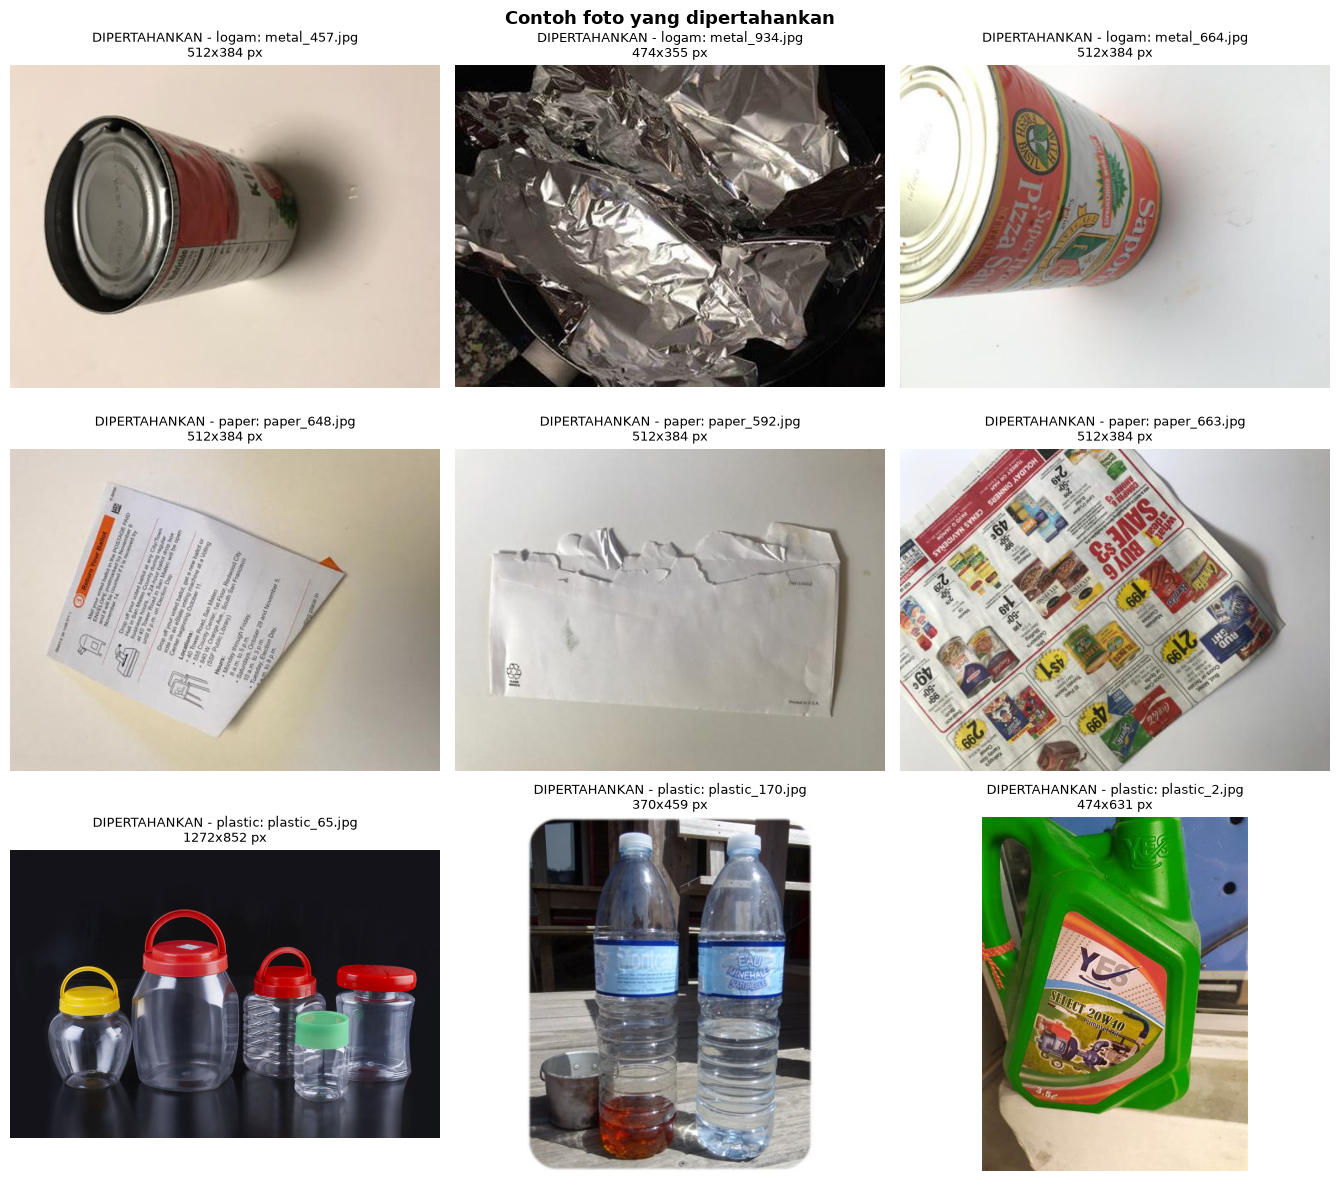

In [6]:
dipertahankan = df[df["status"] == "dipertahankan"]
contoh = pd.concat([g.sample(min(3, len(g)), random_state=1) for _, g in dipertahankan.groupby("kelas")])

daftar = [(baca(DATASET_RAW / r.kelas / r.file), f"DIPERTAHANKAN - {r.kelas}: {r.file}\n{r.lebar}x{r.tinggi} px")
          for r in contoh.itertuples()]
tampilkan(daftar, "Contoh foto yang dipertahankan", HASIL / "contoh_dipertahankan.png")

## 7. Contoh foto yang ditolak 


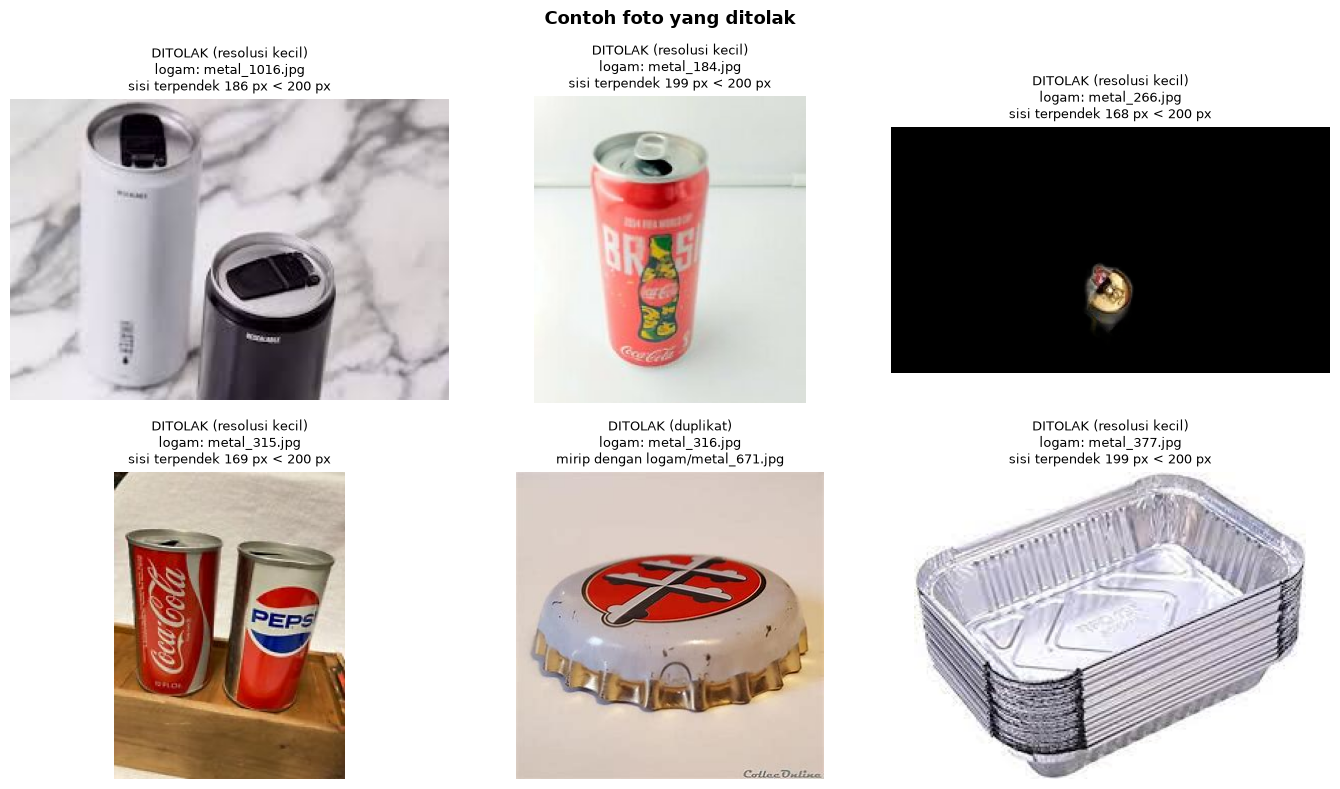

In [7]:
tampil = df[(df["status"] == "ditolak") & (df["lebar"] > 0)].head(6)
if tampil.empty:
    print("Tidak ada foto ditolak yang dapat ditampilkan.")
else:
    daftar = [(baca(DATASET_RAW / r.kelas / r.file), f"DITOLAK ({r.alasan})\n{r.kelas}: {r.file}\n{r.keterangan}")
              for r in tampil.itertuples()]
    tampilkan(daftar, "Contoh foto yang ditolak", HASIL / "contoh_ditolak.png")